# Modelo Oculto de Markov (HMM): predicción del clima a partir de la humedad
**Actividad didáctica 2-M2** · Ingeniería de Software y Datos · Institución Universitaria Digital de Antioquia
**Estudiante:** Elisabeth Martínez Hernández

Este cuaderno simula **30 días** de clima con un HMM:
- **Estados ocultos:** Soleado, Nublado, Lluvioso (no se observan directamente)
- **Observaciones:** Humedad baja, media, alta (lo que sí se ve)

Las probabilidades son las del ejemplo 1 (*Predicción del clima*) del archivo `HMM Simulations - 10 Examples.html`. Son datos **didácticos**, no meteorológicos reales.

**Cómo usarlo:** menú *Entorno de ejecución → Ejecutar todo* (o `Ctrl + F9`). Las librerías ya vienen instaladas en Colab.

## 1. Librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100

## 2. Definición del modelo λ = (π, A, B)

- **π** (probabilidades iniciales): cómo se elige el estado del día 1.
- **A** (matriz de transición): fila = estado de hoy, columna = estado de mañana.
- **B** (matriz de emisión): fila = estado oculto, columna = humedad observada.

In [2]:
ESTADOS = ["Soleado", "Nublado", "Lluvioso"]
OBSERVACIONES = ["Humedad baja", "Humedad media", "Humedad alta"]

# Probabilidades iniciales
pi = np.array([0.6, 0.3, 0.1])

# Matriz de transición A (filas: estado actual | columnas: estado siguiente)
A = np.array([
    [0.7, 0.2, 0.1],   # Soleado
    [0.3, 0.4, 0.3],   # Nublado
    [0.2, 0.3, 0.5],   # Lluvioso
])

# Matriz de emisión B (filas: estado | columnas: humedad observada)
B = np.array([
    [0.7, 0.2, 0.1],   # Soleado
    [0.2, 0.5, 0.3],   # Nublado
    [0.1, 0.3, 0.6],   # Lluvioso
])

# Se muestran como tablas para revisarlas
print("Probabilidades iniciales (π)")
display(pd.DataFrame([pi], columns=ESTADOS, index=["Prob. inicial"]))
print("Matriz de transición (A)")
display(pd.DataFrame(A, index=ESTADOS, columns=ESTADOS))
print("Matriz de emisión (B)")
display(pd.DataFrame(B, index=ESTADOS, columns=OBSERVACIONES))

Probabilidades iniciales (π)


,Soleado,Nublado,Lluvioso
Prob. inicial,0.6,0.3,0.1


Matriz de transición (A)


,Soleado,Nublado,Lluvioso
Soleado,0.7,0.2,0.1
Nublado,0.3,0.4,0.3
Lluvioso,0.2,0.3,0.5


Matriz de emisión (B)


,Humedad baja,Humedad media,Humedad alta
Soleado,0.7,0.2,0.1
Nublado,0.2,0.5,0.3
Lluvioso,0.1,0.3,0.6


## 3. Validación
Cada distribución de probabilidad debe sumar 1. Si algo no suma 1, el modelo no se puede simular.

In [3]:
assert np.isclose(pi.sum(), 1), "π no suma 1"
assert np.allclose(A.sum(axis=1), 1), "alguna fila de A no suma 1"
assert np.allclose(B.sum(axis=1), 1), "alguna fila de B no suma 1"
print("✔ π, A y B son distribuciones válidas (suman 1).")
print("Suma de filas de A:", A.sum(axis=1))
print("Suma de filas de B:", B.sum(axis=1))

✔ π, A y B son distribuciones válidas (suman 1).
Suma de filas de A: [1. 1. 1.]
Suma de filas de B: [1. 1. 1.]


## 4. Algoritmo de simulación
Pasos (los mismos de la sección *Metodología* del documento):
1. Elegir el estado del día 1 con **π**.
2. Elegir la humedad de ese día con la fila correspondiente de **B**.
3. Para cada día siguiente: elegir el nuevo estado con **A** y luego su humedad con **B**.

La semilla (`42`) hace que el resultado se pueda repetir. Cámbiala para obtener otra secuencia.

In [4]:
N_DIAS = 30
SEMILLA = 42

def simular_hmm(n_dias, pi, A, B, semilla=None):
    """Devuelve dos listas de índices: estados ocultos y observaciones."""
    rng = np.random.default_rng(semilla)
    estados, observaciones = [], []
    estado = rng.choice(len(pi), p=pi)                       # día 1 ~ π
    for _ in range(n_dias):
        estados.append(estado)
        observaciones.append(rng.choice(B.shape[1], p=B[estado]))  # humedad ~ B[estado]
        estado = rng.choice(A.shape[0], p=A[estado])               # día siguiente ~ A[estado]
    return np.array(estados), np.array(observaciones)

estados_idx, obs_idx = simular_hmm(N_DIAS, pi, A, B, SEMILLA)

tabla = pd.DataFrame({
    "Día": np.arange(1, N_DIAS + 1),
    "Estado oculto": [ESTADOS[i] for i in estados_idx],
    "Observación": [OBSERVACIONES[i] for i in obs_idx],
})
print("Primeros 10 días simulados")
display(tabla.head(10))

Primeros 10 días simulados


,Día,Estado oculto,Observación
0,1,Nublado,Humedad media
1,2,Lluvioso,Humedad alta
2,3,Soleado,Humedad alta
3,4,Nublado,Humedad alta
4,5,Soleado,Humedad baja
5,6,Soleado,Humedad alta
6,7,Soleado,Humedad media
7,8,Soleado,Humedad baja
8,9,Soleado,Humedad baja
9,10,Nublado,Humedad media


## 5. Tabla completa de los 30 días

In [5]:
display(tabla)

,Día,Estado oculto,Observación
0,1,Nublado,Humedad media
1,2,Lluvioso,Humedad alta
2,3,Soleado,Humedad alta
3,4,Nublado,Humedad alta
4,5,Soleado,Humedad baja
5,6,Soleado,Humedad alta
6,7,Soleado,Humedad media
7,8,Soleado,Humedad baja
8,9,Soleado,Humedad baja
9,10,Nublado,Humedad media


## 6. Frecuencias y porcentajes
Son frecuencias de **esta** simulación de 30 días; no tienen que coincidir exactamente con las probabilidades del modelo.

In [6]:
# Frecuencia de los estados
frec_estados = (tabla["Estado oculto"].value_counts()
                .reindex(ESTADOS, fill_value=0)
                .rename_axis("Estado").reset_index(name="Cantidad de días"))
frec_estados["Porcentaje"] = (frec_estados["Cantidad de días"] / N_DIAS * 100).round(1).astype(str) + " %"
print("Frecuencia de los estados")
display(frec_estados)

# Frecuencia y porcentaje de humedad
frec_hum = (tabla["Observación"].value_counts()
            .reindex(OBSERVACIONES, fill_value=0)
            .rename_axis("Observación").reset_index(name="Cantidad"))
frec_hum["Porcentaje"] = (frec_hum["Cantidad"] / N_DIAS * 100).round(1).astype(str) + " %"
print("Frecuencia y porcentaje de humedad")
display(frec_hum)

Frecuencia de los estados


,Estado,Cantidad de días,Porcentaje
0,Soleado,12,40.0 %
1,Nublado,12,40.0 %
2,Lluvioso,6,20.0 %


Frecuencia y porcentaje de humedad


,Observación,Cantidad,Porcentaje
0,Humedad baja,11,36.7 %
1,Humedad media,11,36.7 %
2,Humedad alta,8,26.7 %


## 7. Tabla de comparación descriptiva
Para cada estado se toma la humedad **más probable** según la matriz B (Soleado → baja, Nublado → media, Lluvioso → alta) y se cuenta qué humedad salió realmente. Es una tabla descriptiva, no una evaluación de precisión con datos reales.

In [7]:
humedad_mas_probable = {ESTADOS[i]: OBSERVACIONES[B[i].argmax()] for i in range(len(ESTADOS))}
print("Humedad más probable según el estado:", humedad_mas_probable)

tabla["Humedad más probable según estado"] = tabla["Estado oculto"].map(humedad_mas_probable)
comparacion = pd.crosstab(tabla["Humedad más probable según estado"], tabla["Observación"])
comparacion = comparacion.reindex(index=OBSERVACIONES, columns=OBSERVACIONES, fill_value=0)
display(comparacion)

Humedad más probable según el estado: {'Soleado': 'Humedad baja', 'Nublado': 'Humedad media', 'Lluvioso': 'Humedad alta'}


Observación,Humedad baja,Humedad media,Humedad alta
Humedad más probable según estado,,,
Humedad baja,8,2,2
Humedad media,3,7,2
Humedad alta,0,2,4


## 8. Gráficas

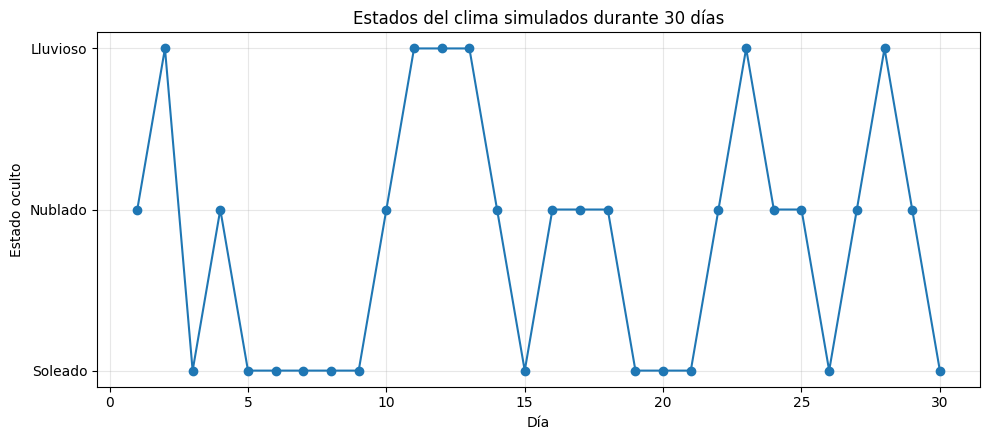

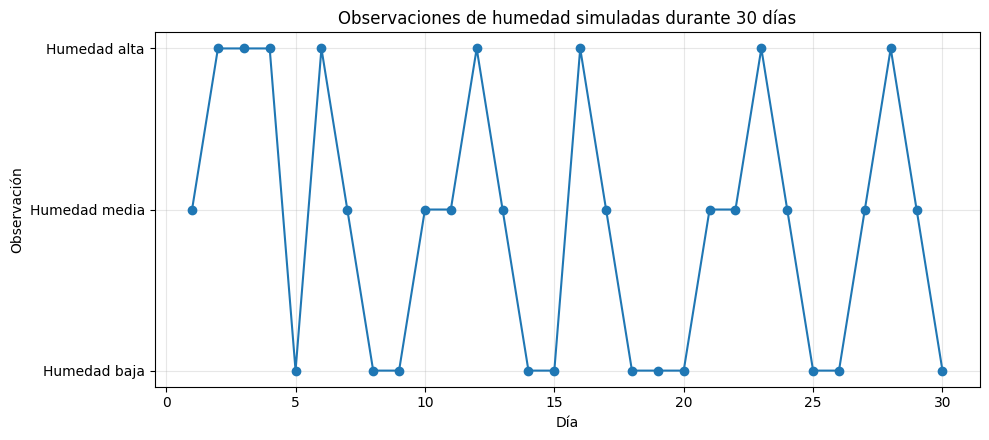

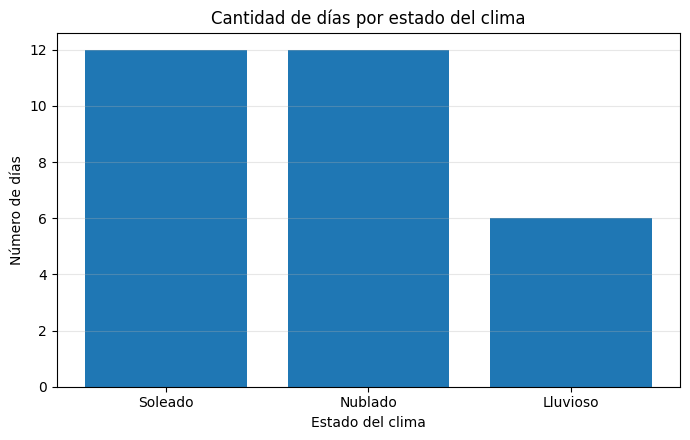

In [8]:
dias = np.arange(1, N_DIAS + 1)

# Gráfica 1: estados del clima
plt.figure(figsize=(10, 4.5))
plt.plot(dias, estados_idx, marker="o")
plt.yticks(range(3), ESTADOS)
plt.title("Estados del clima simulados durante 30 días")
plt.xlabel("Día"); plt.ylabel("Estado oculto"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("grafica_estados.png"); plt.show()

# Gráfica 2: observaciones de humedad
plt.figure(figsize=(10, 4.5))
plt.plot(dias, obs_idx, marker="o")
plt.yticks(range(3), OBSERVACIONES)
plt.title("Observaciones de humedad simuladas durante 30 días")
plt.xlabel("Día"); plt.ylabel("Observación"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("grafica_humedad.png"); plt.show()

# Gráfica 3: cantidad de días por estado
plt.figure(figsize=(7, 4.5))
plt.bar(frec_estados["Estado"], frec_estados["Cantidad de días"])
plt.title("Cantidad de días por estado del clima")
plt.xlabel("Estado del clima"); plt.ylabel("Número de días"); plt.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig("grafica_dias_por_estado.png"); plt.show()

## 9. (Extra) Muchos días: la simulación se acerca a la teoría
Con solo 30 días las frecuencias varían mucho. Con miles de días, la proporción de cada estado se acerca a la **distribución estacionaria** del modelo (el vector `p` que cumple `p = p·A`). Es una forma de comprobar que el código respeta las probabilidades.

,Teórica,"Simulada (10,000 días)"
Soleado,0.4565,0.4515
Nublado,0.2826,0.2823
Lluvioso,0.2609,0.2662


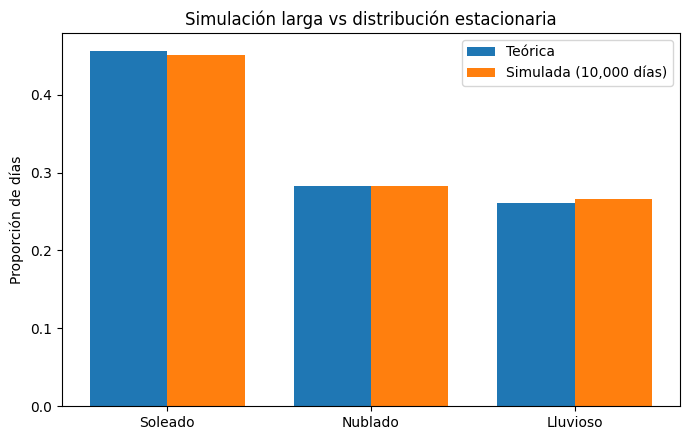

In [9]:
# Distribución estacionaria teórica: autovector izquierdo de A con autovalor 1
valores, vectores = np.linalg.eig(A.T)
p = np.real(vectores[:, np.argmin(np.abs(valores - 1))])
p = p / p.sum()

# Simulación larga
N_LARGO = 10_000
largo_idx, _ = simular_hmm(N_LARGO, pi, A, B, semilla=SEMILLA)
simulada = np.bincount(largo_idx, minlength=3) / N_LARGO

comp = pd.DataFrame({"Teórica": p.round(4), f"Simulada ({N_LARGO:,} días)": simulada.round(4)}, index=ESTADOS)
display(comp)

x = np.arange(3); w = 0.38
plt.figure(figsize=(7, 4.5))
plt.bar(x - w/2, p, w, label="Teórica")
plt.bar(x + w/2, simulada, w, label=f"Simulada ({N_LARGO:,} días)")
plt.xticks(x, ESTADOS); plt.ylabel("Proporción de días")
plt.title("Simulación larga vs distribución estacionaria"); plt.legend()
plt.tight_layout(); plt.savefig("grafica_estacionaria.png"); plt.show()

## 10. Guardar y descargar los resultados
Genera el CSV con la secuencia de 30 días (para subir al repositorio de GitHub) y, si estás en Colab, lo descarga junto con las gráficas.

In [10]:
tabla[["Día", "Estado oculto", "Observación"]].to_csv("resultados_simulacion_hmm.csv", index=False, encoding="utf-8-sig")
print("Archivo guardado: resultados_simulacion_hmm.csv")

try:
    from google.colab import files
    for f in ["resultados_simulacion_hmm.csv", "grafica_estados.png", "grafica_humedad.png",
              "grafica_dias_por_estado.png", "grafica_estacionaria.png"]:
        files.download(f)
except ImportError:
    print("(No estás en Colab: los archivos quedaron en la carpeta actual.)")

Archivo guardado: resultados_simulacion_hmm.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Para reflexionar (útil para el video de sustentación)
1. ¿Qué cambia si modificas la semilla `SEMILLA`? ¿Y si cambias una probabilidad de `A` (sin romper la suma de 1)?
2. ¿Por qué la humedad alta no asegura que el día sea lluvioso? ¿Qué parte del modelo lo expresa?
3. ¿Por qué 30 días no alcanzan para que los porcentajes coincidan con la teoría, pero 10.000 sí?

## Ampliación para la actividad 2-M2: tres escenarios y 300 réplicas por escenario

Se conserva el escenario original del profesor y se añaden dos **escenarios hipotéticos de sensibilidad**, no mediciones reales. Se utiliza una misma lista de semillas para cada escenario (10 000 a 10 299); cada ejecución es reproducible. La precisión indicada por los intervalos corresponde a la estimación Monte Carlo de la media simulada, no a la precisión de pronósticos meteorológicos.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

A_persistencia = np.array([[.85,.10,.05],[.20,.60,.20],[.10,.20,.70]])
B_emisiones = np.array([[.8,.15,.05],[.1,.7,.2],[.05,.2,.75]])
escenarios = {'Base (profesor)': (A, B), 'Mayor persistencia climática': (A_persistencia, B), 'Humedad más asociada al clima': (A, B_emisiones)}
for nombre, (aa,bb) in escenarios.items():
    assert np.allclose(aa.sum(axis=1),1) and np.allclose(bb.sum(axis=1),1), nombre
    assert np.all((aa>=0)&(aa<=1)) and np.all((bb>=0)&(bb<=1)), nombre

filas = []
for nombre,(aa,bb) in escenarios.items():
    for repeticion in range(300):
        xx, yy = simular_hmm(30, pi, aa, bb, semilla=10000+repeticion)
        filas.append({'Escenario': nombre, 'Réplica': repeticion+1,
            'Proporción soleado': np.mean(xx==0), 'Proporción nublado': np.mean(xx==1),
            'Proporción lluvioso': np.mean(xx==2), 'Proporción humedad alta': np.mean(yy==2),
            'Persistencia (29 transiciones)': np.mean(xx[1:]==xx[:-1]),
            'Concordancia modal humedad': np.mean(yy==bb.argmax(axis=1)[xx])})
experimentos = pd.DataFrame(filas)
resumen = (experimentos.melt(id_vars=['Escenario','Réplica'],var_name='Métrica',value_name='Valor')
    .groupby(['Escenario','Métrica'],sort=False)['Valor']
    .agg(N='count', Media='mean', DE='std', Mínimo='min', Máximo='max').reset_index())
resumen['IC95 inferior'] = resumen.Media - 1.96*resumen.DE/np.sqrt(resumen.N)
resumen['IC95 superior'] = resumen.Media + 1.96*resumen.DE/np.sqrt(resumen.N)
display(resumen.round(4))
experimentos.to_csv('resultados_escenarios_900_replicas.csv', index=False)
resumen.to_csv('resumen_estadistico_escenarios.csv', index=False)


In [ ]:
for metrica in ['Proporción humedad alta','Persistencia (29 transiciones)']:
    datos = resumen[resumen['Métrica']==metrica]
    plt.figure(figsize=(10,4))
    plt.bar(datos['Escenario'], datos['Media'], yerr=1.96*datos['DE']/np.sqrt(datos['N']), capsize=5)
    plt.title(f'Comparación de escenarios: {metrica} (IC 95 %)')
    plt.ylabel('Proporción promedio'); plt.xticks(rotation=12,ha='right');plt.tight_layout();plt.show()
